# CineXplain: Content-Based Recommender Demo (Member 1)

A short, presentable walk-through of the content-based recommender.

1. Load the data and build both representations (TF-IDF and sentence embeddings).
2. Compare Top-10 recommendations for a seed movie, side by side.
3. Recommend from a **user profile** (several rated movies), the way the hybrid model will call it.
4. Show the evaluation results.

**Requires:** `data/movies.csv`, ideally `data/movies_enriched.csv`. The first embeddings run takes a few minutes, then it is cached.

In [12]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.content_recommender import ContentRecommender, load_movies, DEFAULT_ENRICHED

pd.set_option("display.max_colwidth", 60)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

movies = load_movies()
print(f"{len(movies):,} movies | TMDB enrichment file found: {DEFAULT_ENRICHED.exists()}")

27,278 movies | TMDB enrichment file found: True


## 1. Build the two representations

In [13]:
rec = ContentRecommender(movies)
rec.fit_tfidf()
rec.fit_embeddings()      # slow the first time, cached afterwards

print("TF-IDF matrix:   ", rec.tfidf_matrix.shape, "(movies x vocabulary)")
print("Embedding matrix:", rec.embeddings.shape, "(movies x 384 dimensions)")

[embeddings] loaded from cache: emb_2ecf530db3.npy
TF-IDF matrix:    (27278, 106599) (movies x vocabulary)
Embedding matrix: (27278, 384) (movies x 384 dimensions)


## 2. Seed movie: TF-IDF vs embeddings

Each side shows the Top-10 most similar movies and their cosine similarity. The *overlap* is the Jaccard
similarity of the two lists (0 = nothing in common, 1 = identical).

In [14]:
def find_movie(title):
    """Exact title match (e.g. 'Toy Story (1995)'); returns movieId or None."""
    hit = movies.loc[movies["title"] == title, "movieId"]
    return int(hit.iloc[0]) if len(hit) else None


def compare(title, k=10):
    mid = find_movie(title)
    if mid is None:
        print(f"'{title}' not found in the movie table, skipping.")
        return
    res = rec.compare_methods(mid, k)
    t = res["tfidf"][["title", "score"]].rename(columns={"title": "TF-IDF", "score": "sim"})
    e = res["embeddings"][["title", "score"]].rename(columns={"title": "Embeddings", "score": "sim"})
    table = pd.concat([t.reset_index(drop=True), e.reset_index(drop=True)], axis=1)
    table.index = range(1, len(table) + 1)
    print(f"Seed: {title}   |   overlap (Jaccard): {res['overlap_jaccard']:.2f}")
    display(table.style.format({"sim": "{:.3f}"}))


compare("Toy Story (1995)")

Seed: Toy Story (1995)   |   overlap (Jaccard): 0.54


,TF-IDF,sim,Embeddings,sim
1,Toy Story 3 (2010),0.565,Toy Story 2 (1999),0.867
2,Toy Story 2 (1999),0.530,Toy Story 3 (2010),0.802
3,Toy Story Toons: Small Fry (2011),0.340,"Toy, The (1982)",0.688
4,Toy Story Toons: Hawaiian Vacation (2011),0.294,Toy Story Toons: Partysaurus Rex (2012),0.649
5,Toy Story Toons: Partysaurus Rex (2012),0.205,Toy Story Toons: Small Fry (2011),0.644
6,Toy Story of Terror (2013),0.204,Toy Story Toons: Hawaiian Vacation (2011),0.628
7,Toy Story That Time Forgot (2014),0.197,Toy Story of Terror (2013),0.594
8,"Wild, The (2006)",0.166,Toys (1992),0.593
9,"NeverEnding Story II: The Next Chapter, The (1990)",0.160,"Christmas Toy, The (1986)",0.583
10,It's Such a Beautiful Day (2012),0.158,Toy Story That Time Forgot (2014),0.573


In [15]:
compare("Titanic (1997)")

Seed: Titanic (1997)   |   overlap (Jaccard): 0.33


,TF-IDF,sim,Embeddings,sim
1,Titanic (1996),0.330,Titanic (1953),0.721
2,Raise the Titanic (1980),0.194,"Chambermaid on the Titanic, The (Femme de chambre du Titanic, La) (1998)",0.631
3,Titanic (1953),0.162,Titanica (1992),0.623
4,Rose Red (2002),0.141,Titanic Town (1998),0.611
5,Dark Eyes (Oci ciornie) (1987),0.138,Raise the Titanic (1980),0.598
6,Revolutionary Road (2008),0.131,Titanic (1996),0.587
7,"Chambermaid on the Titanic, The (Femme de chambre du Titanic, La) (1998)",0.131,Rosetta (1999),0.531
8,Titanica (1992),0.128,"Rose, The (1979)",0.522
9,101 Reykjavik (101 Reykjavík) (2000),0.125,Time of Roses (Ruusujen aika) (1969),0.517
10,Love Affair (1939),0.118,"Wreck of the Mary Deare, The (1959)",0.510


In [16]:
compare("Matrix, The (1999)")

Seed: Matrix, The (1999)   |   overlap (Jaccard): 0.18


,TF-IDF,sim,Embeddings,sim
1,"Matrix Revolutions, The (2003)",0.345,"Matrix Revolutions, The (2003)",0.811
2,"Matrix Reloaded, The (2003)",0.322,"Matrix Reloaded, The (2003)",0.797
3,"Animatrix, The (2003)",0.245,"Animatrix, The (2003)",0.687
4,Not of This Earth (1988),0.203,"Scanner Darkly, A (2006)",0.628
5,Commando (1985),0.179,Hackers (1995),0.623
6,From the Earth to the Moon (1998),0.175,"FBI Story, The (1959)",0.597
7,Red Planet (2000),0.162,Paranoia (2013),0.576
8,V: The Final Battle (1984),0.154,"Machine, The (2013)",0.575
9,Grindhouse (2007),0.151,Hamlet (2000),0.572
10,"Colony, The (2013)",0.148,"Net, The (1995)",0.568


**How to read it**
- TF-IDF rewards shared *words and tokens*: genres, cast names, title words, plot words.
- Embeddings reward shared *meaning*, so they can match movies that use different words for similar stories.
- Low overlap means the two methods surface different movies, which a hybrid model can combine.

## 3. Recommend for a user profile

The hybrid model will not pass one movie, but a user's ratings: `{movieId: rating}`.
The taste vector is the rating-weighted average of the movies rated 4 or higher. Already-rated movies are excluded.

In [17]:
rated = {                       # a made-up user: likes animation/family, dislikes horror
    "Toy Story (1995)": 5.0,
    "Finding Nemo (2003)": 5.0,
    "Shrek (2001)": 4.5,
    "Monsters, Inc. (2001)": 4.0,
    "Scream (1996)": 1.5,
}
profile = {}
for title, r in rated.items():
    mid = find_movie(title)
    if mid is not None:
        profile[mid] = r
    else:
        print(f"(skipping '{title}': not in the movie table)")

print("Profile:", {movies.set_index('movieId').loc[m, 'title']: r for m, r in profile.items()})

Profile: {'Toy Story (1995)': 5.0, 'Finding Nemo (2003)': 5.0, 'Shrek (2001)': 4.5, 'Monsters, Inc. (2001)': 4.0, 'Scream (1996)': 1.5}


In [18]:
if profile:
    for method in ["tfidf", "embeddings"]:
        print(f"\nTop 10 by {method.upper()}")
        display(rec.recommend(profile, method, 10).reset_index(drop=True).style.format({"score": "{:.3f}"}))


Top 10 by TFIDF


,movieId,title,genres,score
0,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.391
1,3114,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,0.355
2,53121,Shrek the Third (2007),Adventure|Animation|Children|Comedy|Fantasy,0.296
3,109965,Shrek the Musical (2013),Children|Comedy|Fantasy|Musical,0.294
4,115879,Toy Story Toons: Small Fry (2011),Adventure|Animation|Children|Comedy|Fantasy,0.273
5,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Romance,0.268
6,115875,Toy Story Toons: Hawaiian Vacation (2011),Adventure|Animation|Children|Comedy|Fantasy,0.263
7,103141,Monsters University (2013),Adventure|Animation|Comedy,0.253
8,111722,Revolt in the Fifth Dimension (1970),Adventure|Animation|Children,0.253
9,99764,It's Such a Beautiful Day (2012),Animation|Comedy|Drama|Fantasy|Sci-Fi,0.252



Top 10 by EMBEDDINGS


,movieId,title,genres,score
0,8360,Shrek 2 (2004),Adventure|Animation|Children|Comedy|Musical|Romance,0.668
1,81711,Scared Shrekless (2010),Adventure|Animation|Comedy,0.659
2,68899,"Monster, The (1925)",Comedy|Horror|Mystery|Sci-Fi,0.646
3,4929,"Toy, The (1982)",Comedy,0.646
4,78499,Toy Story 3 (2010),Adventure|Animation|Children|Comedy|Fantasy|IMAX,0.642
5,4619,Little Monsters (1989),Comedy,0.634
6,64249,Shrek the Halls (2007),Adventure|Animation|Comedy|Fantasy,0.632
7,82698,Demonic Toys (1992),Comedy|Fantasy|Horror,0.632
8,106022,Toy Story of Terror (2013),Animation|Children|Comedy,0.627
9,120468,Toy Story Toons: Partysaurus Rex (2012),Animation|Children|Comedy,0.626


### The interface Member 3 will call

In [19]:
if profile:
    scores = rec.get_content_scores(profile, method="embeddings", top_k=None)
    print(f"Returns a dict {{movieId: score}} for all {len(scores):,} unseen movies, best first.")
    print("First 3:", dict(list(scores.items())[:3]))

Returns a dict {movieId: score} for all 27,273 unseen movies, best first.
First 3: {8360: 0.667795682821503, 81711: 0.6587581745316181, 68899: 0.6458504638889154}


## 4. Evaluation results

Per user (at least 20 ratings): hide 20% of ratings, build the profile from the rest, recommend Top-10, and count a hit if the user rated the movie 4 or higher in the hidden part.

In [20]:
res_path = ROOT / "evaluation" / "results_content.csv"
if res_path.exists():
    results = pd.read_csv(res_path)
    display(results)
else:
    print("evaluation/results_content.csv not found. Run: python evaluation/content_metrics.py --k 10 --users 600")

,method,Precision@10,Recall@10,GenreMatch@10,users_evaluated
0,random,0.0006,0.0003,0.6249,2952
1,tfidf,0.0033,0.0067,0.9840,2952
2,embeddings,0.0013,0.0030,0.8136,2952


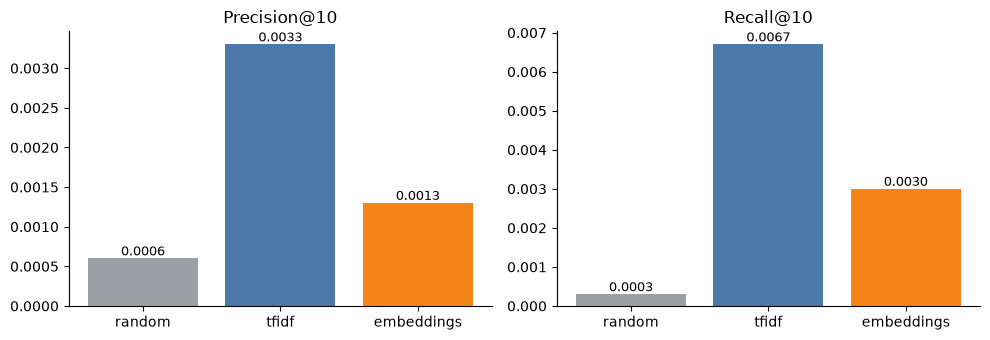

In [21]:
if res_path.exists():
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, col in zip(axes, ["Precision@10", "Recall@10"]):
        ax.bar(results["method"], results[col], color=["#9aa0a6", "#4c78a8", "#f58518"][:len(results)])
        ax.set_title(col)
        for i, v in enumerate(results[col]):
            ax.text(i, v, f"{v:.4f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout(); plt.show()

## Takeaways

- Both methods beat a random baseline; TF-IDF is clearly stronger (about 5x random vs about 2x for embeddings on 2,952 users).
- TF-IDF and embeddings recommend overlapping but different movies, so they can still complement each other in a hybrid.
- Absolute precision is low, as expected for content-only recommendation. This is why the hybrid model (Member 3) combines it with collaborative signals.